# KOSMOS 설계 v2 — 지수 보정과 test 평가 (DeepSeek · Haiku)

순서
1. 개수 벡터에 **라플라스 평활화**(α = 1) → `p ∝ (c + α)^β`로 지수 β를 적용해 정규화
2. **β = 1, β = 3/4**를 고정 적용해 분포 지표 비교 (훈련·검증 분할)
3. **훈련(calibration 148문항)에서 β 그리드 서치** — k=100 고정이라 최적화할 값은 β 하나. 검증(validation 49문항)에서 확인
4. **β를 고정·기록**(`out_calib/frozen_beta.json`)한 뒤, **test 49문항**에서 지표 계산

- β = 1/T. β < 1이면 분포가 평평해진다(쏠림 완화).
- 그리드 기준 지표는 평균 TVD. 참고용으로 Jeffreys(α = 0.5, DESIGN.md의 고정값)도 같이 돌린다.
- 지표: TVD(주), Jensen–Shannon 거리(밑 2), 정규화 Wasserstein-1(서열형·이진형만, 척도 범위로 나눔), 최빈 보기 일치.
- 단계: `c0`, `L0`, `L1agg`(10셀에 같은 β 적용 후 인구 비중 합성), `L1cell`(셀별 TVD 평균).

In [1]:
import json, hashlib, datetime, itertools
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd()
while not (ROOT / "inventory/kgss_clean.parquet").exists():
    ROOT = ROOT.parent
DESIGN = ROOT / "research/design_v2_20261112"
OUT = DESIGN / "analysis/out_calib"; OUT.mkdir(parents=True, exist_ok=True)

MODELS = {
    "deepseek": [ROOT / "raw/v2/deepseek_ultrafast_p1.jsonl"],
    "haiku":    [ROOT / "raw/v2/haiku_p1.jsonl"],
}
ALPHAS = {"laplace": 1.0, "jeffreys": 0.5}
PRIMARY = "laplace"
BETA_FIXED = [1.0, 0.75]
BETA_GRID = np.round(np.arange(0.05, 1.5001, 0.005), 3)
LAM_GRID = np.round(np.arange(0, 1.0001, 0.01), 2)
B_BOOT = 5000
import os
RUN_TEST = os.environ.get("KOSMOS_RUN_TEST") == "1"   # β를 고정·기록한 뒤에만 True로 (4장)
rng = np.random.default_rng(20261112)
pd.set_option("display.precision", 4)
plt.rcParams["font.family"] = "AppleGothic"; plt.rcParams["axes.unicode_minus"] = False

## 1. 텐서 만들기 (246문항 전부 넣되, test는 4장 전까지 계산에 쓰지 않는다)

In [2]:
man = pd.read_csv(DESIGN / "item_manifest_v2.csv", encoding="utf-8-sig").reset_index(drop=True)
man["codes_l"] = man["codes"].apply(json.loads)
ITEMS = man["var"].tolist(); I = len(ITEMS); K = int(man.codes_l.apply(len).max())
CODES = np.full((I, K), np.nan)
for i, cs in enumerate(man.codes_l):
    CODES[i, :len(cs)] = cs
MASK = ~np.isnan(CODES); CODES0 = np.nan_to_num(CODES); NOPT = MASK.sum(1)
CODE2K = [{c: k for k, c in enumerate(cs)} for cs in man.codes_l]
SPLIT = man.split_60_20_20.to_numpy()
TRAIN, VAL, TEST = SPLIT == "calibration", SPLIT == "validation", SPLIT == "test"
ORD = man.scale_type.isin(["ordinal_monotone", "binary"]).to_numpy()

cells = pd.read_csv(DESIGN / "cells.csv", encoding="utf-8-sig").query("level == 'L1'").reset_index(drop=True)
PERSONAS = ["c0", "L0"] + cells.cell_id.tolist(); P = len(PERSONAS); PIDX = {p: j for j, p in enumerate(PERSONAS)}
L1 = slice(2, P); POP_SHARE = (cells.pop_share / cells.pop_share.sum()).to_numpy()

kg = pd.read_parquet(ROOT / "inventory/kgss_clean.parquet"); kg = kg[kg.YEAR == 2023].copy()
kg["band"] = pd.cut(kg.AGE, [18, 30, 40, 50, 60, 200], right=False,
                    labels=["18-29", "30-39", "40-49", "50-59", "60+"]).astype(str)
groups = {"c0": kg, "L0": kg}
for _, c in cells.iterrows():
    groups[c.cell_id] = kg[(kg.SEX == {"남자": 1.0, "여자": 2.0}[c.sex]) & (kg.band == c.age_band)]
H = np.zeros((P, I, K)); HMEAN = np.zeros((P, I)); HSE = np.zeros((P, I))
for p, g in groups.items():
    w_all = g.FINALWT.to_numpy()
    for i, v in enumerate(ITEMS):
        x = g[v].to_numpy(); ok = np.isin(x, CODES[i, MASK[i]]) & (w_all > 0); x, w = x[ok], w_all[ok]
        H[PIDX[p], i] = (w[:, None] * (x[:, None] == CODES[i][None, :])).sum(0) / w.sum()
        m = (w * x).sum() / w.sum(); HMEAN[PIDX[p], i] = m
        HSE[PIDX[p], i] = np.sqrt((w * (x - m) ** 2).sum() / w.sum() / (w.sum() ** 2 / (w ** 2).sum()))
assert np.allclose(H.sum(-1), 1)

def load_counts(paths):
    C = np.zeros((P, I, K), dtype=np.int32); seen = set(); ivar = {v: i for i, v in enumerate(ITEMS)}
    for path in paths:
        for line in open(path, encoding="utf-8"):
            r = json.loads(line)
            if r.get("invalid_type") == "api_error":
                continue
            key = (r["probe_id"], r["sample_idx"])
            if key in seen:
                continue
            seen.add(key)
            if r["valid"]:
                i = ivar[r["var"]]; C[PIDX[r["cell_id"]], i, CODE2K[i][r["parsed"]]] += 1
    return C

MNAMES = list(MODELS); M = len(MNAMES)
C = np.stack([load_counts(MODELS[m]) for m in MNAMES])        # [m, p, i, k]
print("C", C.shape, "| 유효 응답", C.sum((1, 2, 3)), "| 분할", pd.Series(SPLIT).value_counts().to_dict())

C (2, 12, 246, 7) | 유효 응답 [295158 290643] | 분할 {'calibration': 148, 'validation': 49, 'test': 49}


## 2. 공통 연산

In [3]:
def to_prob(C, beta=1.0, alpha=1.0):
    x = (C + alpha * MASK) ** np.asarray(beta) * MASK
    return x / x.sum(-1, keepdims=True)

def levels(X):
    # X[..., p, i, k] → [..., 3, i, k]  (c0, L0, L1agg)
    return np.stack([X[..., 0, :, :], X[..., 1, :, :], np.einsum("...cik,c->...ik", X[..., L1, :, :], POP_SHARE)], -3)

def tvd(a, b): return 0.5 * np.abs(a - b).sum(-1)

def jsd(a, b):
    m = (a + b) / 2
    kl = lambda x, y: np.where(x > 0, x * np.log2(np.where(x > 0, x, 1) / np.where(y > 0, y, 1)), 0).sum(-1)
    return np.sqrt(np.clip(0.5 * kl(a, m) + 0.5 * kl(b, m), 0, None))   # JS 거리 (0~1)

GAP = np.nan_to_num(np.diff(CODES, axis=1))                     # [i, k-1]
RANGE = np.nanmax(CODES, 1) - np.nanmin(CODES, 1)

def argmax_k(p): return np.where(MASK, p, -np.inf).argmax(-1)
UNIF = MASK / NOPT[:, None]
HL = levels(H)                                                   # [3, i, k] (c0·L0는 같은 모집단)
LEVELS = ["c0", "L0", "L1agg", "L1cell"]

def tvd_levels(PB):
    # PB[..., p, i, k] → [..., 4, i]
    a = tvd(levels(PB), HL)
    cell = tvd(PB[..., L1, :, :], H[L1]).mean(-2)
    return np.concatenate([a, cell[..., None, :]], -2)

def boot_ci(x, B=B_BOOT):
    x = np.asarray(x); idx = rng.integers(0, x.shape[-1], (B, x.shape[-1]))
    return np.percentile(x[..., idx].mean(-1), [2.5, 97.5], axis=-1)

In [4]:
def w1_masked(a, b, mask):
    d = np.abs(np.cumsum(a, -1) - np.cumsum(b, -1))[..., :-1]
    v = (d * GAP[mask]).sum(-1) / RANGE[mask]
    return np.where(ORD[mask], v, np.nan)

def metrics_table(PB, mask, label):
    T4 = tvd_levels(PB)[..., mask]                               # [m, 4, i]
    PL = levels(PB)[..., mask, :]; HLm = HL[:, mask]             # [m, 3, i, k], [3, i, k]
    rows = []
    for a, m in enumerate(MNAMES):
        for l, lv in enumerate(LEVELS):
            r = dict(setting=label, model=m, level=lv, tvd=T4[a, l].mean())
            if l < 3:
                r["jsd"] = jsd(PL[a, l], HLm[l]).mean()
                r["w1"] = np.nanmean(w1_masked(PL[a, l], HLm[l], mask))
                mk = MASK[mask]
                r["mode_match"] = (np.where(mk, PL[a, l], -np.inf).argmax(-1) == np.where(mk, HLm[l], -np.inf).argmax(-1)).mean()
            rows.append(r)
    return rows

def baseline_rows(mask, label="균등분포"):
    t = tvd(UNIF[mask], HL[0, mask]).mean(); tc = tvd(UNIF[mask], H[L1][:, mask]).mean()
    return [dict(setting=label, model="—", level=lv, tvd=(tc if lv == "L1cell" else t),
                 jsd=(np.nan if lv == "L1cell" else jsd(UNIF[mask], HL[0, mask]).mean()),
                 w1=(np.nan if lv == "L1cell" else np.nanmean(w1_masked(UNIF[mask], HL[0, mask], mask))))
            for lv in LEVELS]

## 3a. 고정 지수 β = 1, 3/4 (훈련·검증)

In [5]:
rows = []
for split_name, mask in [("train", TRAIN), ("val", VAL)]:
    for aname, alpha in ALPHAS.items():
        for b in BETA_FIXED:
            for r in metrics_table(to_prob(C, b, alpha), mask, f"{aname} β={b}"):
                r["split"] = split_name; rows.append(r)
    for r in baseline_rows(mask):
        r["split"] = split_name; rows.append(r)
fixed = pd.DataFrame(rows); fixed.to_csv(OUT / "fixed_beta_train_val.csv", index=False)
fixed[fixed.setting.str.startswith(PRIMARY) | (fixed.setting == "균등분포")].pivot_table(
    index=["split", "level"], columns=["setting", "model"], values="tvd", sort=False)

setting      laplace β=1.0         laplace β=0.75            균등분포
model             deepseek   haiku       deepseek   haiku       —
split level                                                      
train c0            0.4233  0.4975         0.3640  0.4483  0.3507
      L0            0.4090  0.4832         0.3506  0.4327  0.3507
      L1agg         0.3810  0.4276         0.3367  0.3833  0.3507
      L1cell        0.4201  0.4894         0.3686  0.4374  0.3629
val   c0            0.4583  0.5087         0.3961  0.4560  0.3352
      L0            0.4346  0.5012         0.3717  0.4478  0.3352
      L1agg         0.4046  0.4178         0.3490  0.3721  0.3352
      L1cell        0.4432  0.4857         0.3848  0.4317  0.3534

## 3b. β 그리드 서치 (훈련에서 평균 TVD 최소)

In [6]:
grid = {}
for aname, alpha in ALPHAS.items():
    PG = to_prob(C[None], BETA_GRID[:, None, None, None, None], alpha)   # [β, m, p, i, k]
    grid[aname] = tvd_levels(PG)                                           # [β, m, 4, i]
    del PG

best = {}
rows = []
for aname, G in grid.items():
    tr = G[..., TRAIN].mean(-1)                                           # [β, m, 4]
    bi = tr.argmin(0)                                                     # [m, 4]
    for a, m in enumerate(MNAMES):
        for l, lv in enumerate(LEVELS):
            b = BETA_GRID[bi[a, l]]
            best[(aname, m, lv)] = float(b)
            rows.append(dict(alpha=aname, model=m, level=lv, beta=b, T=round(1 / b, 3),
                             train_beta1=G[list(BETA_GRID).index(1.0), a, l, TRAIN].mean(), train_best=tr[bi[a, l], a, l],
                             val_beta1=G[list(BETA_GRID).index(1.0), a, l, VAL].mean(), val_best=G[bi[a, l], a, l, VAL].mean()))
gridsum = pd.DataFrame(rows); gridsum.to_csv(OUT / "grid_summary.csv", index=False)
gridsum

,alpha,model,level,beta,T,train_beta1,train_best,val_beta1,val_best
0,laplace,deepseek,c0,0.315,3.175,0.4233,0.2650,0.4583,0.2822
1,laplace,deepseek,L0,0.315,3.175,0.4090,0.2561,0.4346,0.2606
2,laplace,deepseek,L1agg,0.340,2.941,0.3810,0.2672,0.4046,0.2630
3,laplace,deepseek,L1cell,0.310,3.226,0.4201,0.2835,0.4432,0.2852
4,laplace,haiku,c0,0.240,4.167,0.4975,0.2988,0.5087,0.2996
5,laplace,haiku,L0,0.245,4.082,0.4832,0.2886,0.5012,0.2928
6,laplace,haiku,L1agg,0.290,3.448,0.4276,0.2670,0.4178,0.2543
7,laplace,haiku,L1cell,0.250,4.000,0.4894,0.2920,0.4857,0.2855
8,jeffreys,deepseek,c0,0.290,3.448,0.4337,0.2624,0.4694,0.2806
9,jeffreys,deepseek,L0,0.285,3.509,0.4195,0.2538,0.4458,0.2555


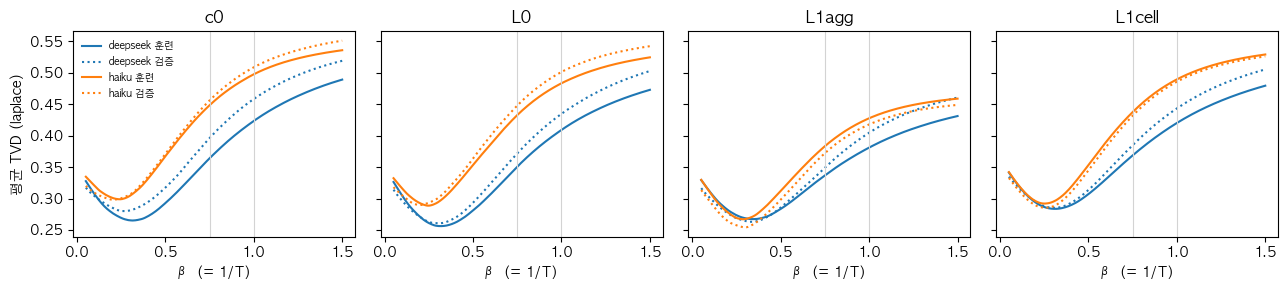

In [7]:
fig, axs = plt.subplots(1, 4, figsize=(13, 3), sharey=True)
G = grid[PRIMARY]
for l, lv in enumerate(LEVELS):
    for a, m in enumerate(MNAMES):
        axs[l].plot(BETA_GRID, G[:, a, l, TRAIN].mean(-1), label=f"{m} 훈련")
        axs[l].plot(BETA_GRID, G[:, a, l, VAL].mean(-1), ls=":", c=axs[l].lines[-1].get_color(), label=f"{m} 검증")
    for b in BETA_FIXED:
        axs[l].axvline(b, c="lightgray", lw=0.8)
    axs[l].set_title(lv); axs[l].set_xlabel("β (= 1/T)")
axs[0].set_ylabel(f"평균 TVD ({PRIMARY})"); axs[0].legend(frameon=False, fontsize=7); plt.tight_layout()

In [8]:
# 균등 혼합 기준선 λ도 훈련에서 고른다: (1−λ)·p(β=1) + λ·균등
best_lam = {}
for a, m in enumerate(MNAMES):
    P1 = to_prob(C[a], 1.0, ALPHAS[PRIMARY])
    for l, lv in enumerate(LEVELS):
        lam = LAM_GRID[:, None, None, None]
        mixed = (1 - lam) * P1[None] + lam * UNIF                         # [λ, p, i, k]
        t = tvd_levels(mixed)[:, l, TRAIN].mean(-1)
        best_lam[(m, lv)] = float(LAM_GRID[t.argmin()])
best_lam

{('deepseek', 'c0'): 0.59,
 ('deepseek', 'L0'): 0.58,
 ('deepseek', 'L1agg'): 0.54,
 ('deepseek', 'L1cell'): 0.6,
 ('haiku', 'c0'): 0.7,
 ('haiku', 'L0'): 0.68,
 ('haiku', 'L1agg'): 0.62,
 ('haiku', 'L1cell'): 0.66}

## 3c. β 고정 기록

이 셀이 `frozen_beta.json`을 쓴다. **이미 파일이 있으면 덮어쓰지 않고 기존 값을 읽는다**(test를 본 뒤 β를 다시 고르지 않도록).

In [9]:
FROZEN = OUT / "frozen_beta.json"
counts_sha = hashlib.sha256(C.tobytes()).hexdigest()
if FROZEN.exists():
    frozen = json.loads(FROZEN.read_text())
    assert frozen["counts_sha256"] == counts_sha, "개수 텐서가 고정 당시와 다르다"
    print("기존 고정값 사용:", FROZEN, frozen["frozen_at"])
else:
    frozen = dict(frozen_at=datetime.datetime.now().isoformat(timespec="seconds"),
                  counts_sha256=counts_sha, primary_alpha=PRIMARY, alphas=ALPHAS,
                  beta_grid=[float(BETA_GRID[0]), float(BETA_GRID[-1]), 0.005], criterion="train mean TVD",
                  beta={f"{a}|{m}|{lv}": b for (a, m, lv), b in best.items()},
                  lam={f"{m}|{lv}": v for (m, lv), v in best_lam.items()})
    FROZEN.write_text(json.dumps(frozen, ensure_ascii=False, indent=1))
    print("고정 기록:", FROZEN)
BETA_STAR = {tuple(k.split("|")): v for k, v in frozen["beta"].items()}
LAM_STAR = {tuple(k.split("|")): v for k, v in frozen["lam"].items()}
pd.Series(frozen["beta"])

기존 고정값 사용: /Users/taewoo/Developer/KOSMOS/research/design_v2_20261112/analysis/out_calib/frozen_beta.json 2026-11-12T13:03:37


laplace|deepseek|c0         0.315
laplace|deepseek|L0         0.315
laplace|deepseek|L1agg      0.340
laplace|deepseek|L1cell     0.310
laplace|haiku|c0            0.240
laplace|haiku|L0            0.245
laplace|haiku|L1agg         0.290
laplace|haiku|L1cell        0.250
jeffreys|deepseek|c0        0.290
jeffreys|deepseek|L0        0.285
jeffreys|deepseek|L1agg     0.310
jeffreys|deepseek|L1cell    0.280
jeffreys|haiku|c0           0.210
jeffreys|haiku|L0           0.215
jeffreys|haiku|L1agg        0.250
jeffreys|haiku|L1cell       0.220
dtype: float64

## 4. test 49문항

In [10]:
if not RUN_TEST:
    print('RUN_TEST=False: test 계산 건너뜀')
else:
    def apply_star(aname):
        # 단계마다 β가 달라서 단계별로 계산한 TVD를 모은다 → [m, 4, i]
        out = np.zeros((M, 4, I))
        for a, m in enumerate(MNAMES):
            for l, lv in enumerate(LEVELS):
                out[a, l] = tvd_levels(to_prob(C[a], BETA_STAR[(aname, m, lv)], ALPHAS[aname]))[l]
        return out

    def jsd_w1_star(aname):
        rows = {}
        for a, m in enumerate(MNAMES):
            for l, lv in enumerate(LEVELS[:3]):
                PL = levels(to_prob(C[a], BETA_STAR[(aname, m, lv)], ALPHAS[aname]))[l, TEST]
                rows[(m, lv)] = (jsd(PL, HL[l, TEST]).mean(), np.nanmean(w1_masked(PL, HL[l, TEST], TEST)))
        return rows

    test_rows = []
    settings = {f"{PRIMARY} β=1": tvd_levels(to_prob(C, 1.0, ALPHAS[PRIMARY])),
                f"{PRIMARY} β=0.75": tvd_levels(to_prob(C, 0.75, ALPHAS[PRIMARY])),
                f"{PRIMARY} β*": apply_star(PRIMARY),
                "jeffreys β*": apply_star("jeffreys")}
    lam_tvd = np.zeros((M, 4, I))
    for a, m in enumerate(MNAMES):
        P1 = to_prob(C[a], 1.0, ALPHAS[PRIMARY])
        for l, lv in enumerate(LEVELS):
            lam = LAM_STAR[(m, lv)]
            lam_tvd[a, l] = tvd_levels((1 - lam) * P1 + lam * UNIF)[l]
    settings["균등 혼합 λ*"] = lam_tvd
    unif_tvd = np.stack([tvd(UNIF, HL[0]), tvd(UNIF, HL[1]), tvd(UNIF, HL[2]), tvd(UNIF, H[L1]).mean(0)])   # [4, i]

    for s, X in settings.items():
        for a, m in enumerate(MNAMES):
            for l, lv in enumerate(LEVELS):
                x = X[a, l, TEST]; ci = boot_ci(x)
                test_rows.append(dict(setting=s, model=m, level=lv, tvd=x.mean(), ci_lo=ci[0], ci_hi=ci[1],
                                      beat_unif=(x < unif_tvd[l, TEST]).mean()))
    for l, lv in enumerate(LEVELS):
        test_rows.append(dict(setting="균등분포", model="—", level=lv, tvd=unif_tvd[l, TEST].mean()))
    test_tbl = pd.DataFrame(test_rows); test_tbl.to_csv(OUT / "test_tvd.csv", index=False)
    display(test_tbl.pivot_table(index="level", columns=["setting", "model"], values="tvd", sort=False))

setting laplace β=1         laplace β=0.75         laplace β*          \
model      deepseek   haiku       deepseek   haiku   deepseek   haiku   
level                                                                   
c0           0.3708  0.5128         0.3138  0.4566     0.2352  0.2884   
L0           0.3610  0.4850         0.3055  0.4285     0.2275  0.2706   
L1agg        0.3613  0.4223         0.3082  0.3778     0.2379  0.2588   
L1cell       0.3929  0.4870         0.3355  0.4325     0.2573  0.2837   

setting jeffreys β*         균등 혼합 λ*            균등분포  
model      deepseek   haiku deepseek   haiku       —  
level                                                 
c0           0.2322  0.2884   0.2544  0.2920  0.3604  
L0           0.2239  0.2682   0.2475  0.2813  0.3604  
L1agg        0.2341  0.2583   0.2615  0.2674  0.3603  
L1cell       0.2540  0.2825   0.2815  0.2924  0.3722

In [11]:
if not RUN_TEST:
    print('RUN_TEST=False: test 계산 건너뜀')
else:
    # β* 에서 JSD · W1 (test)
    js = jsd_w1_star(PRIMARY)
    display(pd.DataFrame({f"{m}": {f"{lv} JSD": js[(m, lv)][0] for lv in LEVELS[:3]} | {f"{lv} W1": js[(m, lv)][1] for lv in LEVELS[:3]}
                  for m in MNAMES}))

,deepseek,haiku
c0 JSD,0.2647,0.3157
L0 JSD,0.2562,0.2986
L1agg JSD,0.2593,0.2870
c0 W1,0.1146,0.1426
L0 W1,0.1131,0.1377
L1agg W1,0.1114,0.1278


In [12]:
if not RUN_TEST:
    print('RUN_TEST=False: test 계산 건너뜀')
else:
    # 모델 차이 (test, 같은 문항): Haiku − DeepSeek. 음수면 Haiku가 더 가깝다
    rows = []
    for s in [f"{PRIMARY} β=1", f"{PRIMARY} β*"]:
        d = settings[s][1] - settings[s][0]                                   # [4, i]
        for l, lv in enumerate(LEVELS):
            x = d[l, TEST]; ci = boot_ci(x)
            rows.append(dict(setting=s, level=lv, haiku_minus_ds=x.mean(), ci_lo=ci[0], ci_hi=ci[1], haiku_better=(x < 0).mean()))
    # β* 가 균등분포보다 나은가 (test)
    for a, m in enumerate(MNAMES):
        for l, lv in enumerate(LEVELS):
            x = settings[f"{PRIMARY} β*"][a, l, TEST] - unif_tvd[l, TEST]; ci = boot_ci(x)
            rows.append(dict(setting=f"{m} β* − 균등", level=lv, haiku_minus_ds=x.mean(), ci_lo=ci[0], ci_hi=ci[1]))
    diff_tbl = pd.DataFrame(rows); diff_tbl.to_csv(OUT / "test_diffs.csv", index=False)
    display(diff_tbl)

,setting,level,haiku_minus_ds,ci_lo,ci_hi,haiku_better
0,laplace β=1,c0,0.1420,0.0796,0.2047,0.1633
1,laplace β=1,L0,0.1240,0.0710,0.1794,0.2653
2,laplace β=1,L1agg,0.0610,0.0061,0.1181,0.3265
3,laplace β=1,L1cell,0.0942,0.0511,0.1374,0.2041
4,laplace β*,c0,0.0532,0.0197,0.0874,0.2857
5,laplace β*,L0,0.0431,0.0134,0.0737,0.2653
6,laplace β*,L1agg,0.0209,-0.0112,0.0536,0.3673
7,laplace β*,L1cell,0.0264,-0.0024,0.0544,0.3265
8,deepseek β* − 균등,c0,-0.1252,-0.1565,-0.0941,NaN
9,deepseek β* − 균등,L0,-0.1328,-0.1649,-0.0976,NaN


In [13]:
if not RUN_TEST:
    print('RUN_TEST=False: test 계산 건너뜀')
else:
    # 참고: 같은 지표를 train / val / test로 나란히 (β*, 라플라스) — 분할 간 일반화 확인
    X = settings[f"{PRIMARY} β*"]
    display(pd.DataFrame({(m, sp): {lv: X[a, l, msk].mean() for l, lv in enumerate(LEVELS)}
                  for a, m in enumerate(MNAMES) for sp, msk in [("train", TRAIN), ("val", VAL), ("test", TEST)]}))

deepseek                   haiku                
          train     val    test   train     val    test
c0       0.2650  0.2822  0.2352  0.2988  0.2996  0.2884
L0       0.2561  0.2606  0.2275  0.2886  0.2928  0.2706
L1agg    0.2672  0.2630  0.2379  0.2670  0.2543  0.2588
L1cell   0.2835  0.2852  0.2573  0.2920  0.2855  0.2837

## 5. 요약: 지표 3종 × 페르소나 × 지수 (test 49문항)

- 지표: **TVD**(낮을수록 좋음), **Wasserstein-1**(서열형·이진형, 척도 범위로 정규화, 낮을수록 좋음), **최빈값 정확도**(모델 최빈 보기 = 사람 최빈 보기, 높을수록 좋음)
- 지수: β = 1, β = 3/4, β* (훈련에서 고른 값, 페르소나 단계마다 따로)
- 라플라스 α = 1. 괄호는 문항 부트스트랩 95% 구간.
- 지수 보정은 한 분포 안의 보기 순서를 바꾸지 않는다. 그래서 **최빈값 정확도는 c0·L0·L1cell에서 β와 무관**하고, 셀을 합치는 L1agg에서만 조금 달라질 수 있다.

In [14]:
if not RUN_TEST:
    print('RUN_TEST=False: test 계산 건너뜀')
else:
    BSET = ["β=1", "β=0.75", "β*"]
    PLABEL = {"c0": "c0 (페르소나 없음)", "L0": "L0 (한국 성인)", "L1agg": "L1 합성", "L1cell": "L1 셀별"}
    def beta_value(bs, m, lv):
        return {"β=1": 1.0, "β=0.75": 0.75}.get(bs) or BETA_STAR[(PRIMARY, m, lv)]

    def w1_full(a, b):
        d = np.abs(np.cumsum(a, -1) - np.cumsum(b, -1))[..., :-1]
        return np.where(ORD, (d * GAP).sum(-1) / RANGE, np.nan)

    def mode_eq(a, b):
        return (np.where(MASK, a, -np.inf).argmax(-1) == np.where(MASK, b, -np.inf).argmax(-1)).astype(float)

    def item_metrics(a, lv, beta):
        PB = to_prob(C[a], beta, ALPHAS[PRIMARY])                         # [p, i, k]
        if lv == "L1cell":
            Pc, Hc = PB[L1], H[L1]
            return dict(tvd=tvd(Pc, Hc).mean(0), w1=w1_full(Pc, Hc).mean(0), mode=mode_eq(Pc, Hc).mean(0))
        l = LEVELS.index(lv); Pl = levels(PB)[l]
        return dict(tvd=tvd(Pl, HL[l]), w1=w1_full(Pl, HL[l]), mode=mode_eq(Pl, HL[l]))

    rows = []
    for a, m in enumerate(MNAMES):
        for lv in LEVELS:
            for bs in BSET:
                b = beta_value(bs, m, lv)
                for met, x in item_metrics(a, lv, b).items():
                    x = x[TEST & ~np.isnan(x)]
                    lo, hi = boot_ci(x)
                    rows.append(dict(model=m, level=lv, beta=bs, beta_value=b, metric=met, mean=x.mean(), lo=lo, hi=hi, n=len(x)))
    UNIF_REF = {"tvd": {lv: unif_tvd[l, TEST].mean() for l, lv in enumerate(LEVELS)},
                "w1": {lv: np.nanmean((w1_full(UNIF, H[L1]).mean(0) if lv == "L1cell" else w1_full(UNIF, HL[LEVELS.index(lv)]))[TEST])
                       for lv in LEVELS}}
    summ = pd.DataFrame(rows); summ.to_csv(OUT / "summary_metrics_test.csv", index=False)

    def fmt(r): return f"{r['mean']:.3f} ({r['lo']:.3f}–{r['hi']:.3f})"
    MLABEL = {"tvd": "TVD ↓", "w1": "Wasserstein-1 ↓", "mode": "최빈값 정확도 ↑"}
    for met in ["tvd", "w1", "mode"]:
        t = summ[summ.metric == met].assign(v=lambda d: d.apply(fmt, axis=1))
        t = t.pivot_table(index="level", columns=["model", "beta"], values="v", aggfunc="first", sort=False)
        t = t.reindex(index=LEVELS, columns=pd.MultiIndex.from_product([MNAMES, BSET]))
        t.index = [PLABEL[i] for i in t.index]
        if met in UNIF_REF:
            t[("균등분포", "")] = [f"{UNIF_REF[met][lv]:.3f}" for lv in LEVELS]
        print(f"\n■ {MLABEL[met]}  (test {int(summ[summ.metric == met].n.max())}문항)")
        display(t)


■ TVD ↓  (test 49문항)


deepseek                                            \
                              β=1               β=0.75                   β*   
c0 (페르소나 없음)  0.371 (0.323–0.419)  0.314 (0.269–0.362)  0.235 (0.205–0.269)   
L0 (한국 성인)    0.361 (0.307–0.415)  0.305 (0.257–0.356)  0.228 (0.198–0.259)   
L1 합성         0.361 (0.305–0.420)  0.308 (0.256–0.360)  0.238 (0.204–0.276)   
L1 셀별         0.393 (0.342–0.447)  0.335 (0.289–0.385)  0.257 (0.226–0.292)   

                            haiku                                            \
                              β=1               β=0.75                   β*   
c0 (페르소나 없음)  0.513 (0.460–0.565)  0.457 (0.406–0.507)  0.288 (0.252–0.326)   
L0 (한국 성인)    0.485 (0.436–0.532)  0.429 (0.384–0.474)  0.271 (0.242–0.302)   
L1 합성         0.422 (0.373–0.473)  0.378 (0.331–0.427)  0.259 (0.224–0.294)   
L1 셀별         0.487 (0.440–0.535)  0.433 (0.389–0.476)  0.284 (0.253–0.314)   

               균등분포  
                     
c0 (페르소나 없음)  0.360  
L0 (한국 성인)    0.360  
L1 합성         0.360  
L1 셀별         0.372


■ Wasserstein-1 ↓  (test 46문항)


deepseek                                            \
                              β=1               β=0.75                   β*   
c0 (페르소나 없음)  0.146 (0.123–0.170)  0.123 (0.102–0.146)  0.115 (0.101–0.129)   
L0 (한국 성인)    0.148 (0.124–0.173)  0.123 (0.101–0.146)  0.113 (0.100–0.127)   
L1 합성         0.142 (0.120–0.166)  0.121 (0.101–0.143)  0.111 (0.098–0.125)   
L1 셀별         0.156 (0.134–0.178)  0.133 (0.113–0.155)  0.121 (0.110–0.134)   

                            haiku                                            \
                              β=1               β=0.75                   β*   
c0 (페르소나 없음)  0.193 (0.165–0.222)  0.168 (0.142–0.197)  0.143 (0.125–0.160)   
L0 (한국 성인)    0.182 (0.158–0.210)  0.158 (0.135–0.186)  0.138 (0.124–0.152)   
L1 합성         0.162 (0.141–0.185)  0.142 (0.121–0.163)  0.128 (0.112–0.145)   
L1 셀별         0.184 (0.163–0.207)  0.161 (0.142–0.182)  0.140 (0.127–0.154)   

               균등분포  
                     
c0 (페르소나 없음)  0.183  
L0 (한국 성인)    0.183  
L1 합성         0.183  
L1 셀별         0.191


■ 최빈값 정확도 ↑  (test 49문항)


deepseek                                            \
                              β=1               β=0.75                   β*   
c0 (페르소나 없음)  0.714 (0.571–0.837)  0.714 (0.571–0.837)  0.714 (0.592–0.837)   
L0 (한국 성인)    0.612 (0.469–0.755)  0.612 (0.469–0.755)  0.612 (0.469–0.755)   
L1 합성         0.490 (0.347–0.633)  0.490 (0.347–0.633)  0.490 (0.347–0.633)   
L1 셀별         0.543 (0.437–0.649)  0.543 (0.433–0.649)  0.543 (0.435–0.647)   

                            haiku                                            
                              β=1               β=0.75                   β*  
c0 (페르소나 없음)  0.612 (0.469–0.755)  0.612 (0.469–0.755)  0.612 (0.469–0.735)  
L0 (한국 성인)    0.633 (0.490–0.755)  0.633 (0.490–0.755)  0.633 (0.490–0.755)  
L1 합성         0.612 (0.469–0.755)  0.633 (0.490–0.776)  0.633 (0.490–0.755)  
L1 셀별         0.586 (0.488–0.686)  0.586 (0.488–0.680)  0.586 (0.484–0.684)

In [15]:
if not RUN_TEST:
    print('RUN_TEST=False: test 계산 건너뜀')
else:
    # 사용된 β* 값
    display(pd.DataFrame({m: {PLABEL[lv]: BETA_STAR[(PRIMARY, m, lv)] for lv in LEVELS} for m in MNAMES}).rename_axis("β*"))

,deepseek,haiku
β*,,
c0 (페르소나 없음),0.315,0.240
L0 (한국 성인),0.315,0.245
L1 합성,0.340,0.290
L1 셀별,0.310,0.250


## 6. 그림

색: DeepSeek = 파랑, Haiku = 주황(범주색 고정 순서). 회색 점선 = 균등분포 기준선.

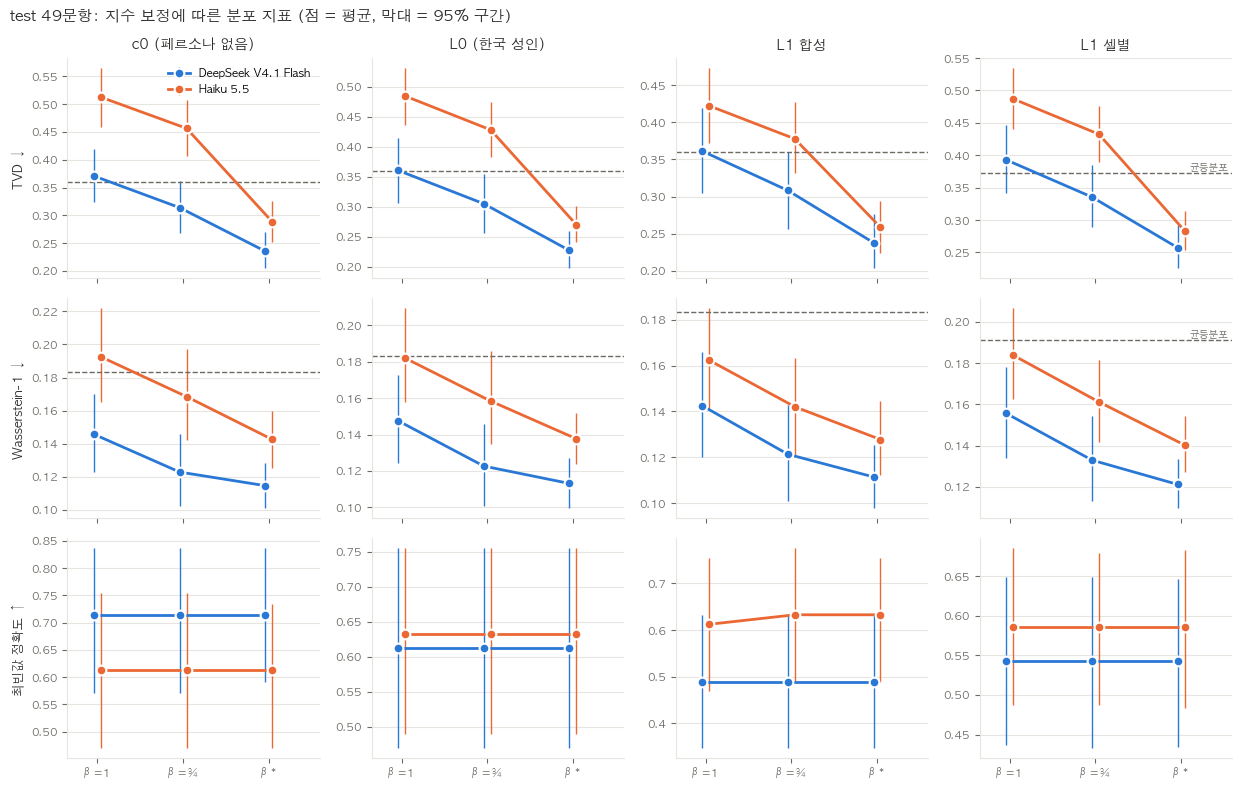

In [16]:
if not RUN_TEST:
    print('RUN_TEST=False: test 계산 건너뜀')
else:
    FIG = OUT / "figs"; FIG.mkdir(exist_ok=True)
    COL = {"deepseek": "#2a78d6", "haiku": "#eb6834"}
    SHADE = {"deepseek": ["#86b6ef", "#3987e5", "#1c5cab"], "haiku": ["#f5b294", "#eb6834", "#a8401a"]}
    NAME = {"deepseek": "DeepSeek V4.1 Flash", "haiku": "Haiku 5.5"}
    INK, MUTED, GRID = "#2b2b29", "#6b6a64", "#e6e5e0"
    plt.rcParams.update({"axes.edgecolor": GRID, "axes.labelcolor": INK, "xtick.color": MUTED, "ytick.color": MUTED,
                         "axes.titlesize": 10, "axes.labelsize": 9, "xtick.labelsize": 8, "ytick.labelsize": 8,
                         "axes.spines.top": False, "axes.spines.right": False})

    # 그림 1: 지표 3 × 페르소나 4, x = 지수 설정
    fig, axs = plt.subplots(3, 4, figsize=(12.5, 8), sharex=True)
    xs = np.arange(len(BSET))
    for r, met in enumerate(["tvd", "w1", "mode"]):
        for c, lv in enumerate(LEVELS):
            ax = axs[r, c]
            for j, m in enumerate(MNAMES):
                d = summ[(summ.metric == met) & (summ.level == lv) & (summ.model == m)].set_index("beta").loc[BSET]
                off = (j - 0.5) * 0.08
                ax.errorbar(xs + off, d["mean"], yerr=[d["mean"] - d["lo"], d["hi"] - d["mean"]], color=COL[m],
                            lw=2, ms=7, marker="o", capsize=0, elinewidth=1, label=NAME[m],
                            markeredgecolor="white", markeredgewidth=1.5)
            if met in UNIF_REF:
                ax.axhline(UNIF_REF[met][lv], ls="--", lw=1, color=MUTED)
                if c == 3:
                    ax.text(2.55, UNIF_REF[met][lv], "균등분포", va="bottom", ha="right", fontsize=7, color=MUTED)
            ax.grid(axis="y", color=GRID, lw=0.8); ax.set_axisbelow(True)
            if r == 0: ax.set_title(PLABEL[lv], color=INK)
            if c == 0: ax.set_ylabel(MLABEL[met])
            ax.set_xticks(xs, ["β=1", "β=¾", "β*"]); ax.set_xlim(-0.35, 2.6)
    axs[0, 0].legend(frameon=False, fontsize=8, loc="upper right")
    fig.suptitle("test 49문항: 지수 보정에 따른 분포 지표 (점 = 평균, 막대 = 95% 구간)", fontsize=11, color=INK, x=0.01, ha="left")
    plt.tight_layout(); fig.savefig(FIG / "fig1_metrics_grid.png", dpi=160, bbox_inches="tight"); plt.show()

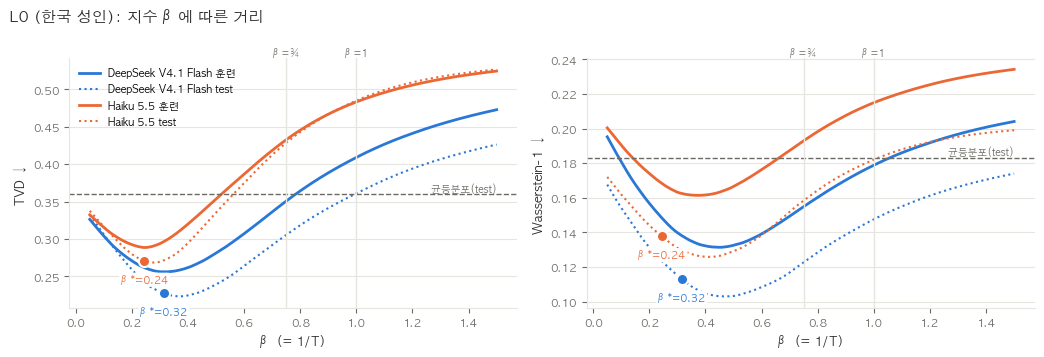

In [17]:
if not RUN_TEST:
    print('RUN_TEST=False: test 계산 건너뜀')
else:
    # 그림 2: β 곡선 (L0) — TVD와 W1, 훈련(실선)·test(점선), β* 표시
    PG1 = to_prob(C[:, 1][None], BETA_GRID[:, None, None, None], ALPHAS[PRIMARY])      # [β, m, i, k]  L0
    curves = {"tvd": tvd(PG1, HL[1]), "w1": w1_full(PG1, HL[1])}                        # [β, m, i]
    fig, axs = plt.subplots(1, 2, figsize=(10.5, 3.6))
    for ax, met in zip(axs, ["tvd", "w1"]):
        for a, m in enumerate(MNAMES):
            tr = np.nanmean(curves[met][:, a][:, TRAIN], -1); te = np.nanmean(curves[met][:, a][:, TEST], -1)
            ax.plot(BETA_GRID, tr, color=COL[m], lw=2, label=f"{NAME[m]} 훈련")
            ax.plot(BETA_GRID, te, color=COL[m], lw=1.5, ls=":", label=f"{NAME[m]} test")
            bs = BETA_STAR[(PRIMARY, m, "L0")]; k = np.argmin(np.abs(BETA_GRID - bs))
            ax.plot(bs, te[k], "o", color=COL[m], ms=8, markeredgecolor="white", markeredgewidth=1.5)
            ax.annotate(f"β*={bs:.2f}", (bs, te[k]), textcoords="offset points", xytext=(0, -16), ha="center", fontsize=7.5, color=COL[m], fontweight="bold",
                        bbox=dict(boxstyle="round,pad=0.15", fc="white", ec="none"))
        ref = UNIF_REF[met]["L0"]
        ax.axhline(ref, ls="--", lw=1, color=MUTED); ax.text(1.5, ref, " 균등분포(test)", va="bottom", ha="right", fontsize=7, color=MUTED)
        for b, lab in [(1.0, "β=1"), (0.75, "β=¾")]:
            ax.axvline(b, color=GRID, lw=1); ax.text(b, ax.get_ylim()[1], lab, fontsize=7, color=MUTED, ha="center", va="bottom")
        ax.set_xlabel("β (= 1/T)"); ax.set_ylabel(MLABEL[met]); ax.grid(axis="y", color=GRID, lw=0.8)
    axs[0].legend(frameon=False, fontsize=7.5)
    fig.suptitle("L0 (한국 성인): 지수 β에 따른 거리", fontsize=11, color=INK, x=0.01, ha="left")
    plt.tight_layout(); fig.savefig(FIG / "fig2_beta_curves_L0.png", dpi=160, bbox_inches="tight"); plt.show()

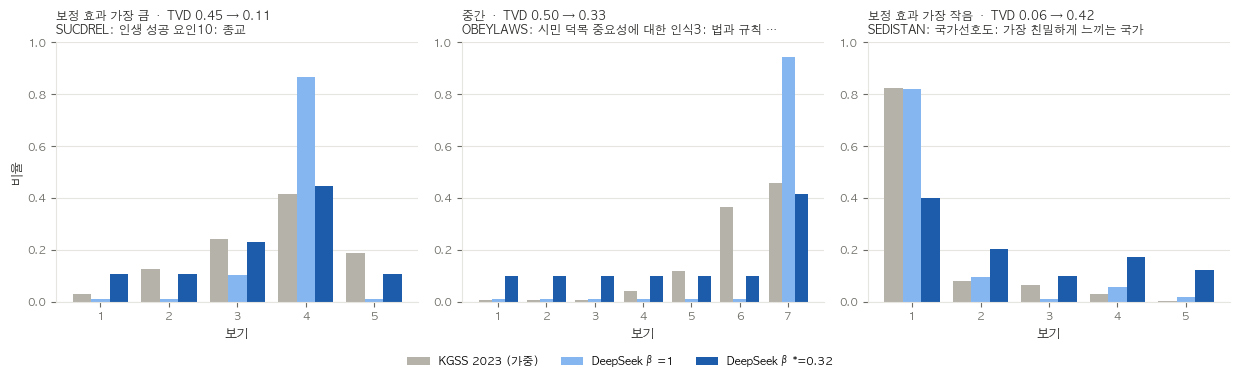

In [18]:
if not RUN_TEST:
    print('RUN_TEST=False: test 계산 건너뜀')
else:
    # 그림 3: 문항 예시 (test, L0, DeepSeek) — 사람 vs β=1 vs β*
    a = MNAMES.index("deepseek"); bstar = BETA_STAR[(PRIMARY, "deepseek", "L0")]
    P1 = levels(to_prob(C[a], 1.0, ALPHAS[PRIMARY]))[1]; PS_ = levels(to_prob(C[a], bstar, ALPHAS[PRIMARY]))[1]
    gain = tvd(P1, HL[1]) - tvd(PS_, HL[1])
    test_idx = np.where(TEST)[0]
    order = test_idx[np.argsort(gain[test_idx])]
    picks = [order[-1], order[len(order) // 2], order[0]]           # 가장 좋아짐 / 중간 / 가장 덜 좋아짐(또는 나빠짐)
    tags = ["보정 효과 가장 큼", "중간", "보정 효과 가장 작음"]
    fig, axs = plt.subplots(1, 3, figsize=(12.5, 3.6))
    for ax, i, tag in zip(axs, picks, tags):
        k = NOPT[i]; x = np.arange(k); w = 0.27
        ax.bar(x - w, HL[1, i, :k], w, color="#b4b2a9", label="KGSS 2023 (가중)")
        ax.bar(x, P1[i, :k], w, color=SHADE["deepseek"][0], label="DeepSeek β=1")
        ax.bar(x + w, PS_[i, :k], w, color=SHADE["deepseek"][2], label=f"DeepSeek β*={bstar:.2f}")
        ax.set_xticks(x, [str(int(cc)) for cc in CODES[i, :k]]); ax.set_xlabel("보기")
        lab = man.label[i]; lab = lab if len(lab) <= 26 else lab[:25] + "…"
        ax.set_title(f"{tag}  ·  TVD {tvd(P1[i], HL[1, i]):.2f} → {tvd(PS_[i], HL[1, i]):.2f}\n{ITEMS[i]}: {lab}", fontsize=8.5, color=INK, loc="left")
        ax.grid(axis="y", color=GRID, lw=0.8); ax.set_axisbelow(True); ax.set_ylim(0, 1)
    axs[0].set_ylabel("비율")
    h_, l_ = axs[0].get_legend_handles_labels()
    fig.legend(h_, l_, frameon=False, fontsize=8, ncol=3, loc="lower center", bbox_to_anchor=(0.5, -0.06))
    plt.tight_layout(); fig.savefig(FIG / "fig3_item_examples.png", dpi=160, bbox_inches="tight"); plt.show()

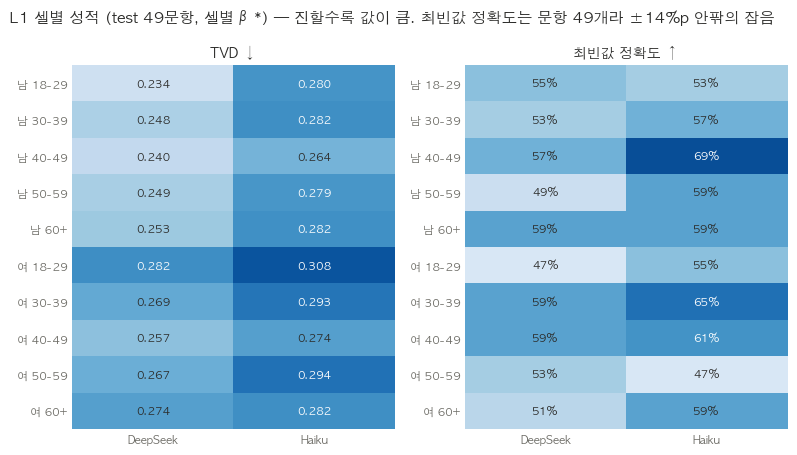

그림 저장: /Users/taewoo/Developer/KOSMOS/research/design_v2_20261112/analysis/out_calib/figs


In [19]:
if not RUN_TEST:
    print('RUN_TEST=False: test 계산 건너뜀')
else:
    # 그림 4: L1 셀별 성적 (test, β*) — TVD와 최빈값 정확도
    cell_lab = [f"{'남' if s == '남자' else '여'} {b}" for s, b in zip(cells.sex, cells.age_band)]
    tv = np.zeros((10, M)); mo = np.zeros((10, M))
    for a, m in enumerate(MNAMES):
        PB = to_prob(C[a], BETA_STAR[(PRIMARY, m, "L1cell")], ALPHAS[PRIMARY])[L1]
        tv[:, a] = tvd(PB, H[L1])[:, TEST].mean(-1); mo[:, a] = mode_eq(PB, H[L1])[:, TEST].mean(-1)
    fig, axs = plt.subplots(1, 2, figsize=(8, 4.6))
    for ax, mat, title, cmap in [(axs[0], tv, "TVD ↓", "Blues"), (axs[1], mo, "최빈값 정확도 ↑", "Blues")]:
        im = ax.imshow(mat, cmap=cmap, aspect="auto", vmin=mat.min() * 0.9, vmax=mat.max() * 1.05)
        for r_ in range(10):
            for c_ in range(M):
                v = mat[r_, c_]; dark = (v - mat.min()) / (mat.max() - mat.min() + 1e-9) > 0.6
                ax.text(c_, r_, f"{v:.3f}" if title.startswith("TVD") else f"{v:.0%}", ha="center", va="center",
                        fontsize=8, color="white" if dark else INK)
        ax.set_xticks(range(M), [NAME[m].split()[0] for m in MNAMES]); ax.set_yticks(range(10), cell_lab)
        ax.set_title(title, color=INK); ax.tick_params(length=0)
        for s in ax.spines.values(): s.set_visible(False)
    fig.suptitle("L1 셀별 성적 (test 49문항, 셀별 β*) — 진할수록 값이 큼. 최빈값 정확도는 문항 49개라 ±14%p 안팎의 잡음", fontsize=11, color=INK, x=0.01, ha="left")
    plt.tight_layout(); fig.savefig(FIG / "fig4_L1_cells.png", dpi=160, bbox_inches="tight"); plt.show()
    print("그림 저장:", FIG)